# 02 · Model 1: alerts that fired together

**Idea.** If one fault causes others, their alerts start within fractions of a second. Grouping alerts by start time is the first view of a cascade.

**Why DBSCAN.** Nobody knows how many cascades a day has, and most alerts belong to none. DBSCAN needs no cluster count and marks isolated alerts as noise (`-1`), which is the right answer for a fault that happened on its own.

**How** (`src/central_logging/time_clusters.py`)
1. Drop `alertIsTpm` and `alertTotalDuration`, convert `alertBegin`/`alertEnd` to nanoseconds, recompute the duration, encode the category (technical 0, organizational 1, other 2)
2. Split the alerts by hour of the day (`alertBegin_hour`)
3. DBSCAN on the start time inside each hour: alerts **less than 200 ms** apart join one group
4. `alert_combined = hour_cluster`, because cluster 3 at 14:00 and cluster 3 at 02:00 are different events

**Settings.** The application ran with `min_samples = 7`: a group needs at least 7 alerts within reach of each other. In Project I the same 200 ms threshold ran with `min_samples = 3`. Both are shown below.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

from central_logging import config, plotting
from central_logging.plotting import SERIES, MUTED, TEXT, TEXT_2

plotting.use_style()
pd.set_option("display.max_colwidth", 90)
RESULTS = ROOT / "results"
FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
from central_logging import time_clusters
from central_logging.generate import alert_day, generate

alerts, truth, plant = generate()
days = sorted(alert_day(alerts).unique())
one_file = alerts[(alert_day(alerts) == days[8]) & (alerts.alertPlc == "A1FTS01")]

df = time_clusters.cluster_by_hour(time_clusters.preprocess(one_file), eps_seconds=0.2, min_samples=3)
print(f"{len(df)} alerts in one PLC file, {(df.Cluster >= 0).sum()} of them in {df[df.Cluster >= 0].alert_combined.nunique()} groups")
df[["alertId", "alertBegin", "alertText", "alertBegin_hour", "Cluster", "alert_combined"]].head()

3305 alerts in one PLC file, 210 of them in 38 groups


,alertId,alertBegin,alertText,alertBegin_hour,Cluster,alert_combined
0,10099973,1713218489935906400,MO1 Motor 1 Uebertemperatur,22,-1,22_-1
1,10099982,1713218554222497200,FB3 Foerderband 17 Stau erkannt,22,-1,22_-1
2,10099990,1713218580693654200,FB3 Foerderband 17 Stau erkannt,22,-1,22_-1
3,10099993,1713218590573260600,OR1 Typwechsel 5 laeuft,22,-1,22_-1
4,10099995,1713218615712486100,FB1 Foerderband 2 Stau erkannt,22,-1,22_-1


The group with the most different messages in that file. `alertBegin` is now nanoseconds; `ms` counts from the first alert of the group, and the last two columns are the hidden labels.

In [3]:
def show(key):
    g = df[df.alert_combined == key].sort_values("alertBegin").copy()
    g.insert(0, "ms", ((g.alertBegin - g.alertBegin.min()) / 1e6).round(1))
    g = g.merge(truth[["alertId", "cascade_id", "cascade_role"]], on="alertId")
    return g[["ms", "alertText", "alert_combined", "cascade_id", "cascade_role"]]

groups = df[df.Cluster >= 0].groupby("alert_combined")
show(groups.alertText.nunique().idxmax())

,ms,alertText,alert_combined,cascade_id,cascade_role
0,0.0,LV2 Lichtvorhang 2 unterbrochen,2_1,3525,root
1,157.4,MO1 Motor 1 Uebertemperatur,2_1,3525,link
2,341.7,FB3 Foerderband 17 Stau erkannt,2_1,3525,link
3,433.6,SE6 Sensor 8 Abgleich erforderlich,2_1,3525,link
4,601.6,SE3 Sensor 4 Abgleich erforderlich,2_1,3525,link
5,754.3,FB5 Foerderband 11 Stau erkannt,2_1,3525,link
6,819.7,FB3 Foerderband 17 Stau erkannt,2_1,3525,link
7,941.0,NH3 Not-Halt Kreis 14 betaetigt,2_1,-1,none


The largest group in the same file is something else: one device repeating one message.

In [4]:
show(groups.size().idxmax()).head(8)

,ms,alertText,alert_combined,cascade_id,cascade_role
0,0.0,OR8 Schichtwechsel Bereich 16,14_0,-1,repeat
1,134.2,OR8 Schichtwechsel Bereich 16,14_0,-1,repeat
2,287.6,OR8 Schichtwechsel Bereich 16,14_0,-1,repeat
3,474.7,OR8 Schichtwechsel Bereich 16,14_0,-1,repeat
4,637.6,OR8 Schichtwechsel Bereich 16,14_0,-1,repeat
5,830.3,OR8 Schichtwechsel Bereich 16,14_0,-1,repeat
6,1003.7,OR8 Schichtwechsel Bereich 16,14_0,-1,repeat
7,1161.2,OR8 Schichtwechsel Bereich 16,14_0,-1,repeat


## Scoring against the hidden labels
The application sees one PLC file at a time, so a chain here means the alerts of one cascade on one PLC on one day (at least two of them). Over week 2 (525 files):
- **chain alerts found:** share of chain alerts that Model 1 put into a group
- **grouped alerts that belong to a chain:** the rest are repeating devices or coincidences
- **pair precision / recall, ARI:** the same comparison counted over pairs of alerts

The sweep below runs Model 1 alone over all week-2 files (`results/model1_sweep.csv`, made by `evaluate.sweep_model1`).

In [5]:
RUN_SWEEP = False

if RUN_SWEEP:
    from central_logging.evaluate import sweep_model1
    settings = [(0.2, m) for m in [2, 3, 4, 5, 6, 7, 8, 10]] + [(e, 3) for e in [0.02, 0.05, 0.1, 0.5, 1.0]]
    sweep_model1(alerts, truth, days[7:], settings).to_csv(RESULTS / "model1_sweep.csv", index=False)

sweep = pd.read_csv(RESULTS / "model1_sweep.csv")
cols = ["eps_seconds", "min_samples", "clustered_alerts", "chain_alerts_found", "clustered_that_are_chain",
        "clustered_that_are_repeats", "pair_precision", "pair_recall", "ari"]
main_rows = sweep[(sweep.eps_seconds == 0.2) & sweep.min_samples.isin([3, 7])][cols]
main_rows.assign(setting=main_rows.min_samples.map({3: "Project I", 7: "application"})).set_index("setting").round(3)

,eps_seconds,min_samples,clustered_alerts,chain_alerts_found,clustered_that_are_chain,clustered_that_are_repeats,pair_precision,pair_recall,ari
setting,,,,,,,,,
Project I,0.2,3,12020,0.452,0.577,0.421,0.197,0.444,0.273
application,0.2,7,1073,0.001,0.014,0.985,0.005,0.002,0.003


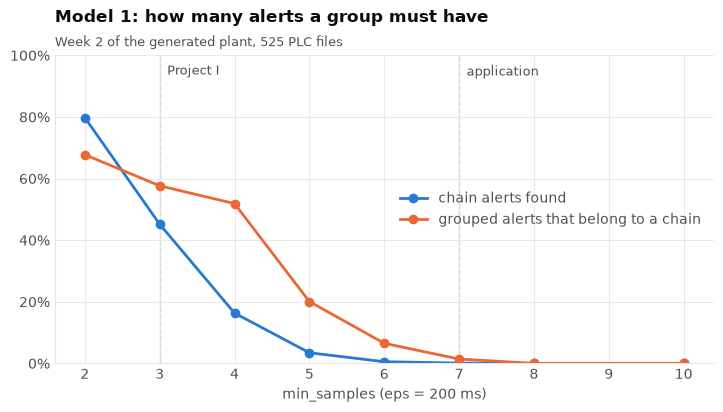

In [6]:
s = sweep[sweep.eps_seconds == 0.2].sort_values("min_samples")
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(s.min_samples, s.chain_alerts_found, marker="o", color=SERIES[0], label="chain alerts found")
ax.plot(s.min_samples, s.clustered_that_are_chain, marker="o", color=SERIES[1], label="grouped alerts that belong to a chain")
for m, lab in [(3, "Project I"), (7, "application")]:
    ax.axvline(m, color=MUTED, lw=1, ls="--", zorder=0)
    ax.text(m + 0.1, 0.97, lab, color=TEXT_2, fontsize=9, va="top")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("min_samples (eps = 200 ms)")
ax.set_title("Model 1: how many alerts a group must have")
plotting.subtitle(ax, "Week 2 of the generated plant, 525 PLC files")
ax.legend(loc="center right")
fig.savefig(FIG / "model1_min_samples.png")
plt.show()

And the threshold itself, at `min_samples = 3`:

In [7]:
sweep[sweep.min_samples == 3].sort_values("eps_seconds")[cols].round(3)

,eps_seconds,min_samples,clustered_alerts,chain_alerts_found,clustered_that_are_chain,clustered_that_are_repeats,pair_precision,pair_recall,ari
8,0.02,3,73,0.003,0.658,0.342,0.640,0.002,0.004
9,0.05,3,1140,0.030,0.397,0.602,0.088,0.020,0.033
10,0.10,3,3958,0.124,0.482,0.517,0.117,0.095,0.105
1,0.20,3,12020,0.452,0.577,0.421,0.197,0.444,0.273
11,0.50,3,21170,0.701,0.508,0.489,0.167,0.858,0.279
12,1.00,3,21863,0.740,0.520,0.474,0.175,0.913,0.294


## Takeaway
- At 200 ms with `min_samples = 7`, Model 1 finds 0.1% of the chain alerts, and 98.5% of what it groups is a device repeating one message: cascades of 3 to 12 alerts rarely have 7 alerts within reach of each other. With `min_samples = 3` it finds 45% of the chain alerts, and 58% of what it groups belongs to a chain.
- Both settings matter. Going from 3 to 7 takes Model 1 from about half of the chain alerts to almost none; widening the threshold to 0.5 s finds 70% but adds more coincidences. The right values depend on how long and how fast the plant's real chains are, so on plant data they have to be checked per PLC with the engineers, by looking at the data.
- Repeating devices are the main source of wrong groups. Model 1 only sees time, so a sensor firing ten times looks like a chain. That is where Model 2's view of the text helps.